In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import expit, logit
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    brier_score_loss, precision_recall_curve,
    f1_score, precision_score, recall_score
)

warnings.filterwarnings("ignore")
np.random.seed(42)

BASE = Path("/content")
OUT = BASE / "member4_outputs"
OUT.mkdir(exist_ok=True)

LABELS = [
    "toxic", "obscene", "threat",
    "insult", "identity_hate", "sexual_explicit"
]

THRESHOLDS = {
    "toxic": 0.720,
    "obscene": 0.900,
    "threat": 0.863,
    "insult": 0.789,
    "identity_hate": 0.821,
    "sexual_explicit": 0.920
}

def find_file(name):
    files = list(BASE.rglob(name))
    return files[0] if files else None

val_path = find_file("val_predictions.parquet")
test_path = find_file("test_predictions.parquet")

if val_path is None or test_path is None:
    raise FileNotFoundError(
        "Upload val_predictions.parquet and test_predictions.parquet."
    )

val = pd.read_parquet(val_path)
test = pd.read_parquet(test_path)

# Load thresholds if available
threshold_path = find_file("thresholds.json")

if threshold_path:
    with open(threshold_path) as f:
        saved_thresholds = json.load(f)

    if "thresholds" in saved_thresholds:
        saved_thresholds = saved_thresholds["thresholds"]

    THRESHOLDS.update({
        k: float(v)
        for k, v in saved_thresholds.items()
        if k in LABELS
    })

# Extract probabilities and true labels
P_VAL = val[[f"prob_{l}" for l in LABELS]].to_numpy(dtype=float)
Y_VAL = val[[f"true_{l}" for l in LABELS]].to_numpy(dtype=int)

P_TEST = test[[f"prob_{l}" for l in LABELS]].to_numpy(dtype=float)
Y_TEST = test[[f"true_{l}" for l in LABELS]].to_numpy(dtype=int)

EPS = 1e-6

def clip(p):
    return np.clip(p, EPS, 1 - EPS)

print("Validation rows:", len(val))
print("Test rows:", len(test))
print("Thresholds:", THRESHOLDS)
print("Output folder:", OUT)

Validation rows: 176643
Test rows: 176644
Thresholds: {'toxic': 0.7201715111732483, 'obscene': 0.8998277187347412, 'threat': 0.8625832796096802, 'insult': 0.7885831594467163, 'identity_hate': 0.8207569718360901, 'sexual_explicit': 0.9196425676345825}
Output folder: /content/member4_outputs


Section 2 — Calibration before calibration
This measures how trustworthy the original predicted probabilities are using:
- Brier score: lower is better.
- ECE: lower means predicted probabilities more closely match observed positive rates.
- Positive and negative counts for each label.

In [2]:
def ece(y, p, bins=10):
    # Divide predictions into equal-frequency bins
    order = np.argsort(p)
    groups = np.array_split(order, min(bins, len(order)))

    error = 0

    for group in groups:
        if len(group) == 0:
            continue

        predicted = p[group].mean()
        actual = y[group].mean()

        error += len(group) / len(y) * abs(actual - predicted)

    return float(error)


def calibration_table(P, Y, stage):
    rows = []

    for j, label in enumerate(LABELS):
        rows.append({
            "label": label,
            "stage": stage,
            "total": len(Y),
            "positives": int(Y[:, j].sum()),
            "negatives": int((Y[:, j] == 0).sum()),
            "brier_score": brier_score_loss(Y[:, j], P[:, j]),
            "ECE": ece(Y[:, j], P[:, j]),
            "mean_probability": P[:, j].mean(),
            "actual_positive_rate": Y[:, j].mean()
        })

    return pd.DataFrame(rows)


# Test is used only to report the original calibration metrics.
before = calibration_table(P_TEST, Y_TEST, "Before calibration")

display(before.round(4))

before.to_csv(
    OUT / "calibration_before.csv",
    index=False
)

,label,stage,total,positives,negatives,brier_score,ECE,mean_probability,actual_positive_rate
0,toxic,Before calibration,176644,14131,162513,0.0460,0.0450,0.1244,0.0800
1,obscene,Before calibration,176644,941,175703,0.0055,0.0067,0.0120,0.0053
2,threat,Before calibration,176644,407,176237,0.0038,0.0050,0.0073,0.0023
3,insult,Before calibration,176644,10452,166192,0.0354,0.0378,0.0966,0.0592
4,identity_hate,Before calibration,176644,1318,175326,0.0119,0.0159,0.0234,0.0075
5,sexual_explicit,Before calibration,176644,420,176224,0.0035,0.0044,0.0068,0.0024


Section 3 — Fit calibration models
We compare three approaches:
1. Temperature scaling — the primary method.
2. Platt scaling — comparison.
3. Isotonic regression — comparison.
All calibrators are fitted on validation predictions only. Test predictions are transformed using the fitted calibrators.

In [3]:
TEMPERATURES = {}
PLATT = {}
ISOTONIC = {}

P_VAL_CAL = np.zeros_like(P_VAL)
P_TEST_CAL = np.zeros_like(P_TEST)
P_TEST_PLATT = np.zeros_like(P_TEST)
P_TEST_ISO = np.zeros_like(P_TEST)

for j, label in enumerate(LABELS):

    x = logit(clip(P_VAL[:, j]))
    y = Y_VAL[:, j]

    # 1. Temperature scaling
    def loss(temp):
        p = clip(expit(x / temp))
        return -np.mean(
            y * np.log(p) + (1-y) * np.log(1-p)
        )

    result = minimize_scalar(
        loss,
        bounds=(0.05, 10),
        method="bounded"
    )

    temp = float(result.x)
    TEMPERATURES[label] = temp

    P_VAL_CAL[:, j] = expit(x / temp)
    P_TEST_CAL[:, j] = expit(
        logit(clip(P_TEST[:, j])) / temp
    )

    # 2. Platt scaling
    lr = LogisticRegression(
        C=1e6,
        max_iter=1000
    )

    lr.fit(x.reshape(-1, 1), y)

    a = float(lr.coef_[0, 0])
    b = float(lr.intercept_[0])

    PLATT[label] = {"a": a, "b": b}

    P_TEST_PLATT[:, j] = expit(
        a * logit(clip(P_TEST[:, j])) + b
    )

    # 3. Isotonic regression
    iso = IsotonicRegression(
        out_of_bounds="clip",
        y_min=0,
        y_max=1
    )

    iso.fit(P_VAL[:, j], y)
    ISOTONIC[label] = iso

    P_TEST_ISO[:, j] = iso.predict(P_TEST[:, j])


# Compare all methods on test
after_temp = calibration_table(
    P_TEST_CAL, Y_TEST, "Temperature"
)

after_platt = calibration_table(
    P_TEST_PLATT, Y_TEST, "Platt"
)

after_iso = calibration_table(
    P_TEST_ISO, Y_TEST, "Isotonic"
)

results = pd.concat(
    [before, after_temp, after_platt, after_iso],
    ignore_index=True
)

display(
    results[
        ["label", "stage", "positives",
         "brier_score", "ECE"]
    ].round(4)
)

results.to_csv(
    OUT / "calibration_before_after.csv",
    index=False
)

# Save temperature settings
with open(OUT / "calibration_config.json", "w") as f:
    json.dump({
        "method": "temperature",
        "temperatures": TEMPERATURES,
        "labels": LABELS
    }, f, indent=2)

,label,stage,positives,brier_score,ECE
0,toxic,Before calibration,14131,0.0460,0.0450
1,obscene,Before calibration,941,0.0055,0.0067
2,threat,Before calibration,407,0.0038,0.0050
3,insult,Before calibration,10452,0.0354,0.0378
4,identity_hate,Before calibration,1318,0.0119,0.0159
5,sexual_explicit,Before calibration,420,0.0035,0.0044
6,toxic,Temperature,14131,0.0453,0.0493
7,obscene,Temperature,941,0.0054,0.0074
8,threat,Temperature,407,0.0038,0.0053
9,insult,Temperature,10452,0.0348,0.0415


Reliability diagram

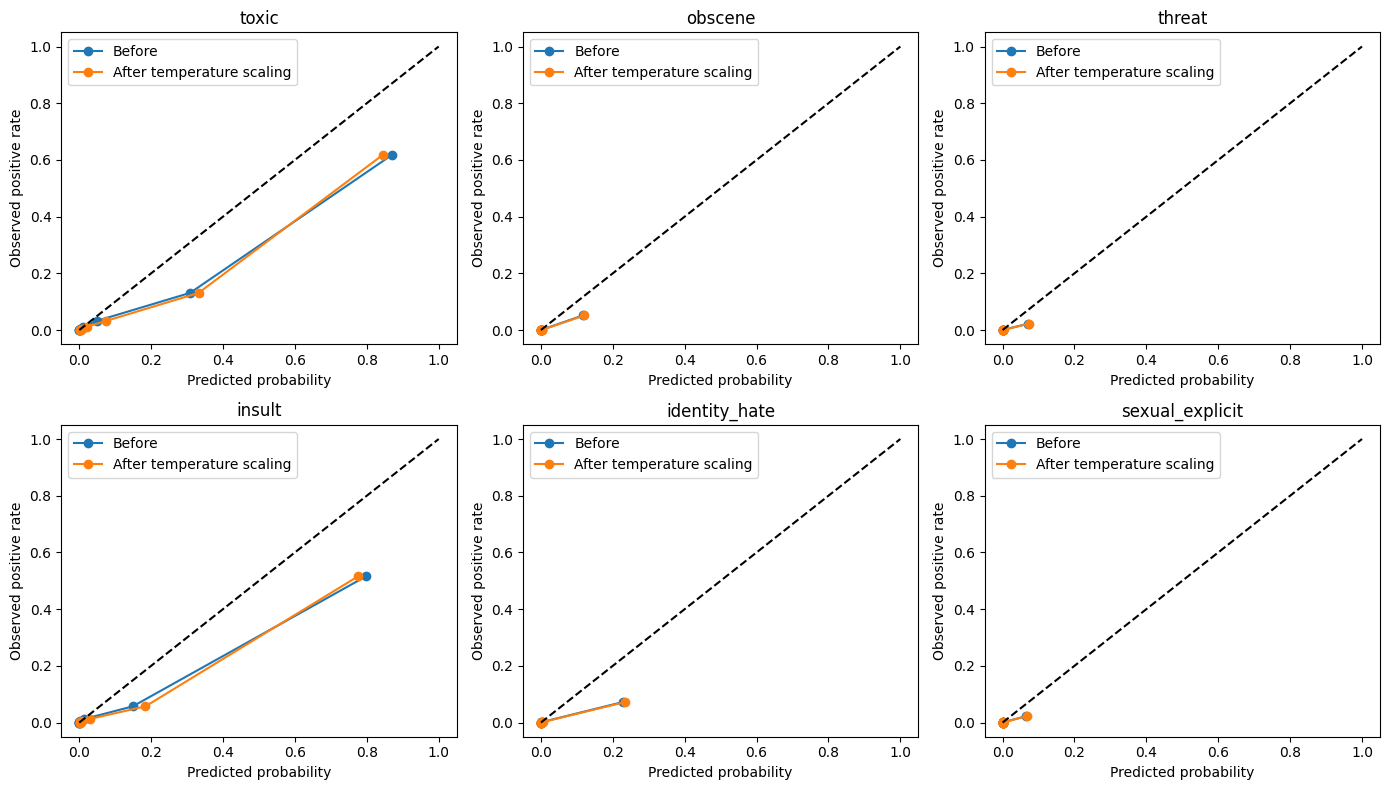

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for j, label in enumerate(LABELS):
    ax = axes.ravel()[j]

    for P, name in [
        (P_TEST, "Before"),
        (P_TEST_CAL, "After temperature scaling")
    ]:
        groups = np.array_split(
            np.argsort(P[:, j]), 10
        )

        predicted = [P[g, j].mean() for g in groups]
        actual = [Y_TEST[g, j].mean() for g in groups]

        ax.plot(
            predicted, actual,
            marker="o", label=name
        )

    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(label)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed positive rate")
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUT / "reliability_diagrams.png",
    dpi=150
)
plt.show()

Section 4 — Tune thresholds on calibrated validation data
After temperature scaling, retune the six thresholds using validation data only. This code chooses the threshold that maximizes F1 for each label.

In [5]:
CAL_THRESHOLDS = {}

for j, label in enumerate(LABELS):
    precision, recall, thresholds = precision_recall_curve(
        Y_VAL[:, j],
        P_VAL_CAL[:, j]
    )

    if len(thresholds) == 0:
        CAL_THRESHOLDS[label] = THRESHOLDS[label]
        continue

    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    )

    best_index = np.nanargmax(f1)
    CAL_THRESHOLDS[label] = float(thresholds[best_index])

print("New calibrated thresholds:")

for label, threshold in CAL_THRESHOLDS.items():
    print(f"{label}: {threshold:.3f}")

with open(OUT / "thresholds_calibrated.json", "w") as f:
    json.dump(CAL_THRESHOLDS, f, indent=2)

New calibrated thresholds:
toxic: 0.688
obscene: 0.880
threat: 0.853
insult: 0.747
identity_hate: 0.797
sexual_explicit: 0.906


Section 5 — Abstention and human-review policy
The policy sends a comment for human review when any label's probability is close to its decision threshold.

In [6]:
THR_VECTOR = np.array([
    CAL_THRESHOLDS[label] for label in LABELS
])

def calculate_margin(P):
    distance = np.abs(
        logit(clip(P)) - logit(clip(THR_VECTOR))
    )
    return distance.min(axis=1)


M_VAL = calculate_margin(P_VAL_CAL)
M_TEST = calculate_margin(P_TEST_CAL)

REVIEW_BUDGET = 0.10

# Select the review band on validation only
DELTA = float(np.quantile(M_VAL, REVIEW_BUDGET))

print("Selected review band:", round(DELTA, 4))

Selected review band: 1.1446


In [7]:
def evaluate_policy(delta):
    auto = M_TEST >= delta

    predictions = (
        P_TEST_CAL >= THR_VECTOR
    ).astype(int)

    if not auto.any():
        return {
            "delta": delta,
            "coverage": 0,
            "review_rate": 1,
            "n_auto": 0,
            "n_review": len(test),
            "comment_error_rate": np.nan,
            "macro_f1": np.nan
        }

    actual = Y_TEST[auto]
    predicted = predictions[auto]

    return {
        "delta": float(delta),
        "n_auto": int(auto.sum()),
        "n_review": int((~auto).sum()),
        "coverage": float(auto.mean()),
        "review_rate": float((~auto).mean()),

        # Fraction of automatically decided comments
        # with at least one incorrect label
        "comment_error_rate": float(
            np.any(actual != predicted, axis=1).mean()
        ),

        "macro_f1": float(np.mean([
            f1_score(
                actual[:, j],
                predicted[:, j],
                zero_division=0
            )
            for j in range(len(LABELS))
        ])),

        "precision_micro": precision_score(
            actual, predicted,
            average="micro",
            zero_division=0
        ),

        "recall_micro": recall_score(
            actual, predicted,
            average="micro",
            zero_division=0
        )
    }


# Evaluate no-review policy and selected policy on test
no_review = evaluate_policy(0)
selected_policy = evaluate_policy(DELTA)

print("No human review:")
print(no_review)

print("\nSelected human-review policy:")
print(selected_policy)

# Calculate the reduction in automatic comment errors
if (
    no_review["comment_error_rate"] > 0
    and not np.isnan(selected_policy["comment_error_rate"])
):
    reduction = 100 * (
        1 - selected_policy["comment_error_rate"]
        / no_review["comment_error_rate"]
    )
    print(f"\nChange in comment error rate: {reduction:.2f}% reduction")

No human review:
{'delta': 0.0, 'n_auto': 176644, 'n_review': 0, 'coverage': 1.0, 'review_rate': 0.0, 'comment_error_rate': 0.06595185797423066, 'macro_f1': 0.5716426131750594, 'precision_micro': 0.6638705186216498, 'recall_micro': 0.6893274061223752}

Selected human-review policy:
{'delta': 1.1446263084321235, 'n_auto': 159266, 'n_review': 17378, 'coverage': 0.9016213400964652, 'review_rate': 0.0983786599035348, 'comment_error_rate': 0.020286815767332638, 'macro_f1': 0.5760126321772399, 'precision_micro': 0.867195242814668, 'recall_micro': 0.7359125315391085}

Change in comment error rate: 69.24% reduction


Plot the coverage/error trade-off

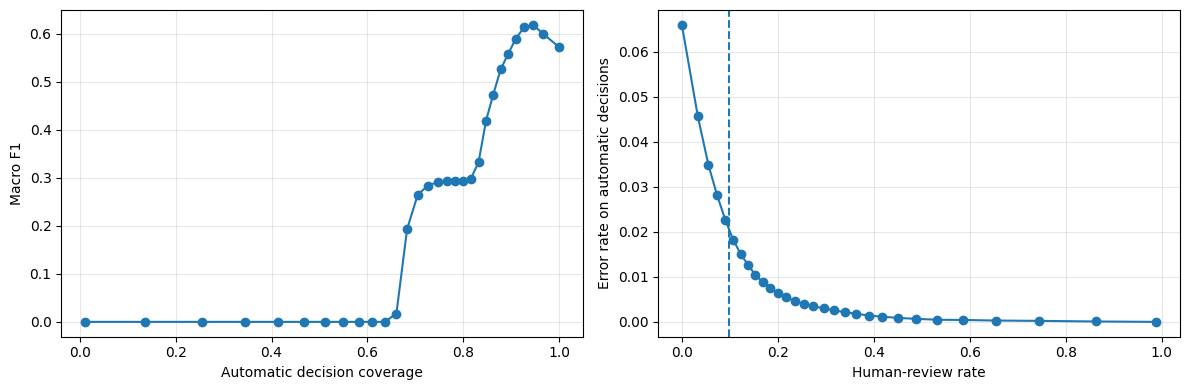

In [8]:
deltas = np.linspace(
    0,
    max(float(np.quantile(M_VAL, 0.99)), 0.01),
    30
)

sweep = pd.DataFrame([
    evaluate_policy(d) for d in deltas
])

sweep.to_csv(
    OUT / "abstention_sweep_test.csv",
    index=False
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    sweep["coverage"],
    sweep["macro_f1"],
    marker="o"
)
axes[0].set_xlabel("Automatic decision coverage")
axes[0].set_ylabel("Macro F1")
axes[0].grid(alpha=0.3)

axes[1].plot(
    sweep["review_rate"],
    sweep["comment_error_rate"],
    marker="o"
)
axes[1].axvline(
    selected_policy["review_rate"],
    linestyle="--"
)
axes[1].set_xlabel("Human-review rate")
axes[1].set_ylabel("Error rate on automatic decisions")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUT / "abstention_tradeoff.png",
    dpi=150
)
plt.show()

# Save the chosen policy for deployment
with open(OUT / "abstention_config.json", "w") as f:
    json.dump({
        "delta_logit_margin": DELTA,
        "review_budget": REVIEW_BUDGET,
        "thresholds_calibrated": CAL_THRESHOLDS,
        "labels": LABELS
    }, f, indent=2)

Section 6 — Fairness check for human review
This checks whether particular identity groups are sent for review more often than others. It also measures toxic-label FPR and FNR on the automatically decided comments.

In [9]:
IDENTITY_COLS = [
    "male", "female", "transgender", "other_gender",
    "heterosexual", "homosexual_gay_or_lesbian",
    "bisexual", "other_sexual_orientation",
    "christian", "jewish", "muslim", "hindu", "buddhist",
    "atheist", "other_religion", "black", "white", "asian",
    "latino", "other_race_or_ethnicity",
    "physical_disability", "intellectual_or_learning_disability",
    "psychiatric_or_mental_illness", "other_disability"
]

groups = [
    col for col in IDENTITY_COLS
    if col in test.columns
]

if groups:
    if "has_identity_labels" in test.columns:
        annotated = (
            test["has_identity_labels"]
            .fillna(False)
            .astype(bool)
            .to_numpy()
        )
    else:
        annotated = (
            test[groups].notna().any(axis=1).to_numpy()
        )

    predictions = (
        P_TEST_CAL >= THR_VECTOR
    ).astype(int)

    auto = M_TEST >= DELTA
    rows = []

    for group in groups:
        member = (
            annotated
            & (test[group].fillna(0).to_numpy() >= 0.5)
        )

        if member.sum() < 30:
            continue

        auto_group = member & auto

        toxic_negative = auto_group & (Y_TEST[:, 0] == 0)
        toxic_positive = auto_group & (Y_TEST[:, 0] == 1)

        rows.append({
            "group": group,
            "n_group": int(member.sum()),
            "n_auto": int(auto_group.sum()),
            "n_review": int((member & ~auto).sum()),

            "review_rate": float(
                (member & ~auto).sum() / member.sum()
            ),

            "n_toxic_negatives_auto": int(
                toxic_negative.sum()
            ),

            "n_toxic_positives_auto": int(
                toxic_positive.sum()
            ),

            "FPR_toxic_auto": (
                float(predictions[toxic_negative, 0].mean())
                if toxic_negative.sum() else np.nan
            ),

            "FNR_toxic_auto": (
                float(
                    (predictions[toxic_positive, 0] == 0).mean()
                )
                if toxic_positive.sum() else np.nan
            )
        })

    group_table = pd.DataFrame(rows)

    group_table.to_csv(
        OUT / "abstention_by_group.csv",
        index=False
    )

    display(
        group_table.sort_values(
            "review_rate",
            ascending=False
        ).round(4)
    )

else:
    print("No identity columns found. Fairness audit skipped.")

,group,n_group,n_auto,n_review,review_rate,n_toxic_negatives_auto,n_toxic_positives_auto,FPR_toxic_auto,FNR_toxic_auto
12,black,1506,672,834,0.5538,566,106,0.0265,0.2547
4,homosexual_gay_or_lesbian,891,411,480,0.5387,363,48,0.0110,0.4583
13,white,2501,1207,1294,0.5174,1027,180,0.0127,0.3722
3,heterosexual,117,57,60,0.5128,53,4,0.0000,0.5000
16,other_race_or_ethnicity,50,25,25,0.5000,22,3,0.0000,0.0000
7,muslim,2284,1344,940,0.4116,1192,152,0.0126,0.5526
2,transgender,273,161,112,0.4103,145,16,0.0069,0.6250
17,psychiatric_or_mental_illness,489,343,146,0.2986,294,49,0.0136,0.0612
6,jewish,734,522,212,0.2888,474,48,0.0127,0.5000
15,latino,192,141,51,0.2656,135,6,0.0000,0.5000


Section 7 — SHAP explainability
This section needs Member 2's actual model files. It may take a while, even with a GPU, so start with a small sample.

In [10]:
import torch
import shap
import sys
import shutil
from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# --------------------------------------------------
# 1. Set up paths
# --------------------------------------------------
BASE = Path("/content")

MODEL_DIR = BASE / "final_model"
TOKENIZER_DIR = BASE / "tokenizer"
PREPROCESS_FILE = BASE / "toxic_preprocessing.py"

# --------------------------------------------------
# 2. Create folders if they don't exist
# --------------------------------------------------
MODEL_DIR.mkdir(exist_ok=True)
TOKENIZER_DIR.mkdir(exist_ok=True)

# Move model files if uploaded directly into /content
for filename in ["config.json", "model.safetensors"]:
    source = BASE / filename
    destination = MODEL_DIR / filename

    if source.exists() and not destination.exists():
        shutil.move(str(source), str(destination))

# Move tokenizer files if uploaded directly into /content
for filename in ["tokenizer.json", "tokenizer_config.json",
                 "special_tokens_map.json", "vocab.txt"]:
    source = BASE / filename
    destination = TOKENIZER_DIR / filename

    if source.exists() and not destination.exists():
        shutil.move(str(source), str(destination))

# --------------------------------------------------
# 3. Check required files
# --------------------------------------------------
if not (MODEL_DIR / "config.json").exists():
    raise FileNotFoundError(
        "config.json is missing. Upload your model config.json."
    )

if not (MODEL_DIR / "model.safetensors").exists():
    raise FileNotFoundError(
        "model.safetensors is missing. Upload your trained model weights."
    )

if not (TOKENIZER_DIR / "tokenizer.json").exists():
    raise FileNotFoundError(
        "tokenizer.json is missing. Upload your tokenizer.json."
    )

if not PREPROCESS_FILE.exists():
    raise FileNotFoundError(
        "Upload toxic_preprocessing.py into /content. "
        "It must contain the clean_text() function."
    )

# --------------------------------------------------
# 4. Import preprocessing function
# --------------------------------------------------
sys.path.insert(0, str(BASE))
from toxic_preprocessing import clean_text

# --------------------------------------------------
# 5. Load tokenizer and trained model
# --------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(
    str(TOKENIZER_DIR)
)

model = AutoModelForSequenceClassification.from_pretrained(
    str(MODEL_DIR)
).to(device)

model.eval()

MAX_LEN = 240

# --------------------------------------------------
# 6. Confirm everything loaded correctly
# --------------------------------------------------
print("Device:", device)
print("Model loaded successfully!")
print("Tokenizer loaded successfully!")
print("Maximum sequence length:", MAX_LEN)
print("Label mapping:", model.config.id2label)

print("\nModel files:", [p.name for p in MODEL_DIR.iterdir()])
print("Tokenizer files:", [p.name for p in TOKENIZER_DIR.iterdir()])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Device: cuda
Model loaded successfully!
Tokenizer loaded successfully!
Maximum sequence length: 240
Label mapping: {0: 'toxic', 1: 'obscene', 2: 'threat', 3: 'insult', 4: 'identity_hate', 5: 'sexual_explicit'}

Model files: ['model.safetensors', 'config.json']
Tokenizer files: ['tokenizer.json', 'tokenizer_config.json']


In [11]:
if tokenizer.pad_token is None:
    # If eos_token is available, use it; otherwise add a new [PAD] token
    if tokenizer.eos_token is not None:
        tokenizer.pad_token = tokenizer.eos_token
    else:
        tokenizer.add_special_tokens({'pad_token': '[PAD]'})
        model.resize_token_embeddings(len(tokenizer))

@torch.no_grad()
def predict_probs(texts, batch_size=16):
    texts = [
        clean_text(str(text))
        for text in texts
    ]

    outputs = []

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        tokens = tokenizer(
            batch_texts,
            truncation=True,
            max_length=MAX_LEN,
            padding=True,
            return_tensors="pt"
        ).to(device)

        logits = model(**tokens).logits.float()

        probabilities = torch.sigmoid(logits)
        outputs.append(probabilities.cpu().numpy())

    return np.vstack(outputs)


# Quick test
example = "I am a gay woman and I loved this article."

print(
    dict(zip(
        LABELS,
        np.round(predict_probs([example])[0], 4)
    ))
)

{'toxic': np.float32(0.6581), 'obscene': np.float32(0.0018), 'threat': np.float32(0.0021), 'insult': np.float32(0.0476), 'identity_hate': np.float32(0.8843), 'sexual_explicit': np.float32(0.0035)}


In [12]:
TEXT_COL = next(
    (
        col for col in ["text_raw", "text", "comment_text"]
        if col in test.columns
    ),
    None
)

if TEXT_COL is None:
    raise ValueError("No text column found in test predictions.")

parts = []

# Sample toxic and harmless comments
for target in [1, 0]:
    subset = test[test["true_toxic"] == target]

    if len(subset):
        parts.append(
            subset.sample(
                min(60, len(subset)),
                random_state=42
            )
        )

# Add identity-annotated comments if columns are available
identity_cols = [
    col for col in [
        "homosexual_gay_or_lesbian",
        "muslim", "black", "jewish"
    ]
    if col in test.columns
]

if identity_cols:
    subset = test[
        test[identity_cols].fillna(0).ge(0.5).any(axis=1)
    ]

    if len(subset):
        parts.append(
            subset.sample(
                min(60, len(subset)),
                random_state=42
            )
        )

sample = (
    pd.concat(parts)
    .drop_duplicates()
    .head(180)
    .reset_index(drop=True)
)

texts = [
    clean_text(str(text))
    for text in sample[TEXT_COL]
]

masker = shap.maskers.Text(tokenizer)

explainer = shap.Explainer(
    lambda text_list: predict_probs(list(text_list)),
    masker,
    output_names=LABELS
)

shap_values = explainer(
    texts,
    batch_size=8
)

print("SHAP values calculated for", len(texts), "comments.")

PartitionExplainer explainer: 181it [04:06,  1.40s/it]

SHAP values calculated for 180 comments.


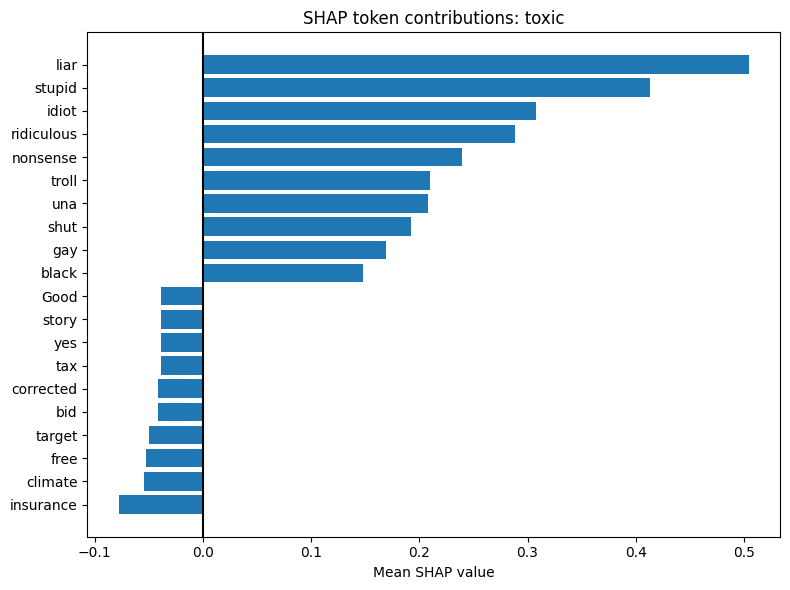

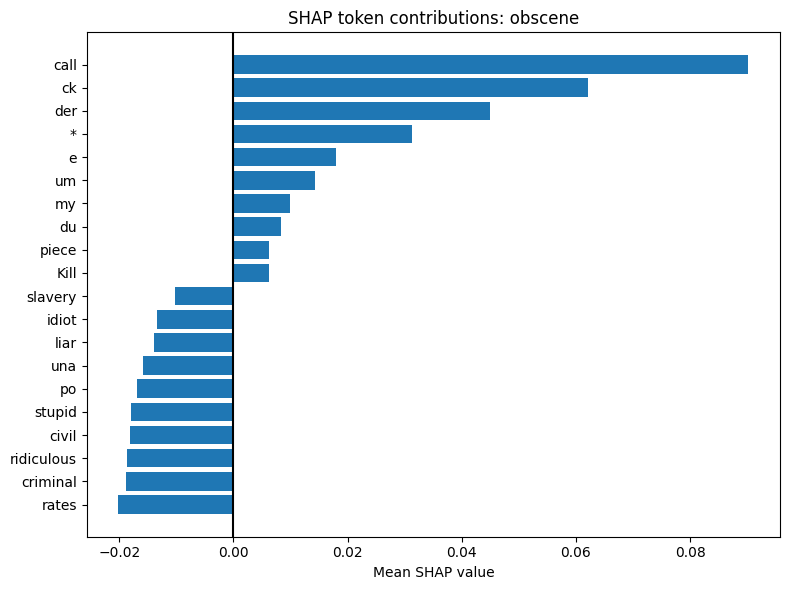

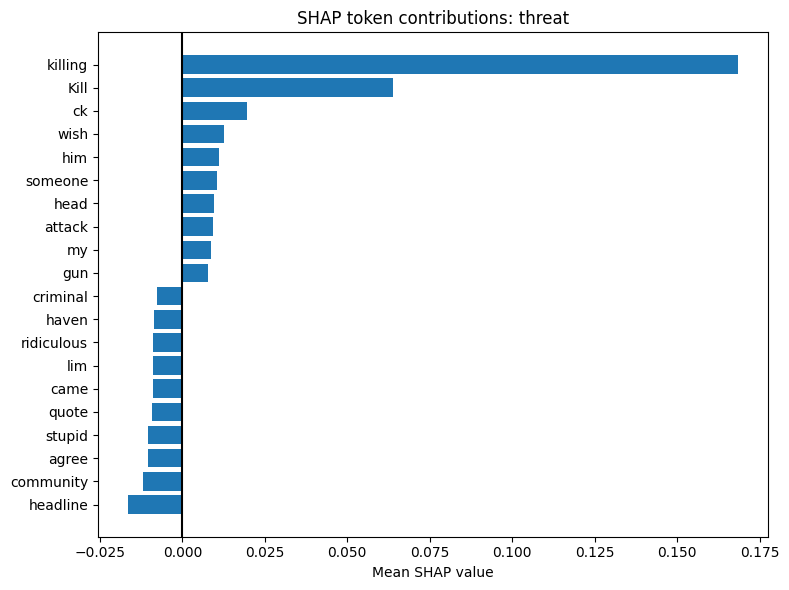

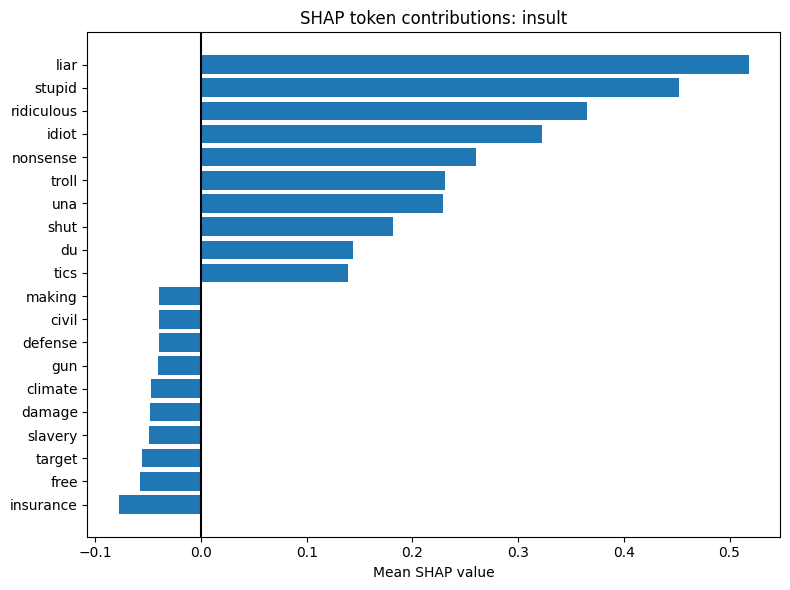

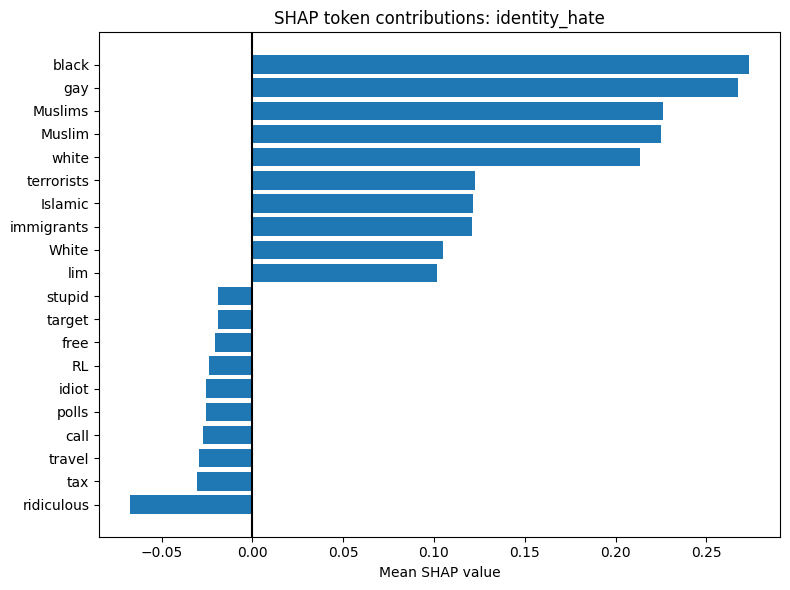

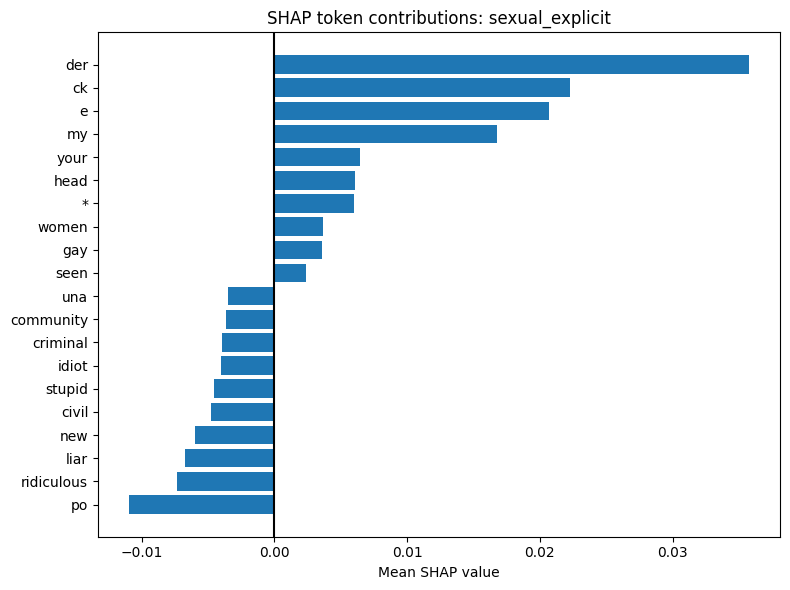

In [13]:
for j, label in enumerate(LABELS):

    token_map = {}

    for i in range(len(shap_values)):
        tokens = shap_values[i].data
        values = shap_values[i].values[:, j]

        for token, value in zip(tokens, values):
            token = str(token).strip()

            if token:
                token_map.setdefault(token, []).append(
                    float(value)
                )

    token_table = pd.DataFrame([
        {
            "token": token,
            "mean_shap": np.mean(values),
            "count": len(values)
        }
        for token, values in token_map.items()
        if len(values) >= 3
    ])

    if token_table.empty:
        continue

    token_table["direction"] = np.where(
        token_table["mean_shap"] > 0,
        "pushes probability up",
        "pushes probability down"
    )

    token_table.to_csv(
        OUT / f"shap_tokens_{label}.csv",
        index=False
    )

    top_positive = token_table.nlargest(
        10, "mean_shap"
    )

    top_negative = token_table.nsmallest(
        10, "mean_shap"
    )

    top = pd.concat([
        top_negative,
        top_positive
    ]).drop_duplicates("token").sort_values("mean_shap")

    plt.figure(figsize=(8, 6))
    plt.barh(top["token"], top["mean_shap"])
    plt.axvline(0, color="black")
    plt.title(f"SHAP token contributions: {label}")
    plt.xlabel("Mean SHAP value")
    plt.tight_layout()

    plt.savefig(
        OUT / f"shap_global_{label}.png",
        dpi=150
    )

    plt.show()
    plt.close()

In [14]:
raw_probs = predict_probs(
    sample[TEXT_COL].astype(str).tolist()
)

sample["p_toxic"] = raw_probs[:, 0]
sample["pred_toxic"] = (
    sample["p_toxic"] >= THRESHOLDS["toxic"]
)

sample["true_toxic"] = sample["true_toxic"].astype(int)

cases = {
    "true_positive": (
        (sample["true_toxic"] == 1)
        & sample["pred_toxic"]
    ),

    "true_negative": (
        (sample["true_toxic"] == 0)
        & ~sample["pred_toxic"]
    ),

    "false_positive": (
        (sample["true_toxic"] == 0)
        & sample["pred_toxic"]
    ),

    "false_negative": (
        (sample["true_toxic"] == 1)
        & ~sample["pred_toxic"]
    )
}

for case_name, condition in cases.items():

    indexes = list(sample.index[condition][:2])

    for number, index in enumerate(indexes):
        html = shap.plots.text(
            shap_values[index, :, 0],
            display=False
        )

        (OUT / f"shap_{case_name}_{number}.html").write_text(
            str(html),
            encoding="utf-8"
        )

print("Local SHAP HTML examples saved.")

Local SHAP HTML examples saved.


In [15]:
for term in ["gay", "muslim", "black", "jewish", "lesbian"]:

    contributions = []

    for i in range(len(sample)):

        if sample.loc[i, "true_toxic"] != 0:
            continue

        for token, value in zip(
            shap_values[i].data,
            shap_values[i].values[:, 0]
        ):
            if str(token).strip().lower() == term:
                contributions.append(float(value))

    if contributions:
        print(
            term,
            "| Mean toxic-label SHAP:",
            round(np.mean(contributions), 4),
            "| Occurrences:",
            len(contributions)
        )

gay | Mean toxic-label SHAP: 0.0982 | Occurrences: 12
muslim | Mean toxic-label SHAP: 0.0996 | Occurrences: 13
black | Mean toxic-label SHAP: 0.1093 | Occurrences: 17
jewish | Mean toxic-label SHAP: 0.0098 | Occurrences: 4


In [16]:
example = "I am a gay woman and I loved this article."

example_probs = predict_probs([example])[0]

print("Example:", example)

for label, probability in zip(LABELS, example_probs):
    print(f"{label}: {probability:.4f}")

Example: I am a gay woman and I loved this article.
toxic: 0.6581
obscene: 0.0018
threat: 0.0021
insult: 0.0476
identity_hate: 0.8843
sexual_explicit: 0.0035


In [17]:
def calibrated_probabilities(text):
    raw = predict_probs([text])[0]

    return np.array([
        expit(
            logit(clip(raw[j]))
            / TEMPERATURES[label]
        )
        for j, label in enumerate(LABELS)
    ])


def explain(text, top_k=5):
    clean = clean_text(str(text))

    shap_result = explainer([clean])[0]
    probabilities = calibrated_probabilities(clean)

    flags = [
        label
        for j, label in enumerate(LABELS)
        if probabilities[j] >= CAL_THRESHOLDS[label]
    ]

    top_tokens = {}

    for label in flags:
        j = LABELS.index(label)

        # Largest positive contributions first
        order = np.argsort(
            -shap_result.values[:, j]
        )[:top_k]

        top_tokens[label] = [
            {
                "token": str(shap_result.data[i]).strip(),
                "contribution": round(
                    float(shap_result.values[i, j]), 4
                )
            }
            for i in order
        ]

    return {
        "probabilities": {
            label: round(float(probabilities[j]), 4)
            for j, label in enumerate(LABELS)
        },
        "flags": flags,
        "top_tokens": top_tokens
    }


print(explain("I am a gay woman and I loved this article."))

{'probabilities': {'toxic': 0.6339, 'obscene': 0.0033, 'threat': 0.0028, 'insult': 0.0782, 'identity_hate': 0.8613, 'sexual_explicit': 0.0052}, 'flags': ['identity_hate'], 'top_tokens': {'identity_hate': [{'token': 'gay', 'contribution': 0.8766}, {'token': 'woman', 'contribution': 0.0667}, {'token': '', 'contribution': 0.0}, {'token': '', 'contribution': -0.0}, {'token': 'I', 'contribution': -0.0035}]}}


In [18]:
def decide(text):
    probabilities = calibrated_probabilities(text)

    margins = np.abs(
        logit(clip(probabilities))
        - logit(clip(THR_VECTOR))
    )

    uncertain = [
        LABELS[j]
        for j in range(len(LABELS))
        if margins[j] < DELTA
    ]

    flags = [
        label
        for j, label in enumerate(LABELS)
        if probabilities[j] >= CAL_THRESHOLDS[label]
    ]

    if uncertain:
        details = explain(text)

        return {
            "decision": "HUMAN_REVIEW",
            "reason": "Probability is close to a label threshold",
            "uncertain_labels": uncertain,
            "flags_if_automatic": flags,
            "probabilities": details["probabilities"],
            "top_tokens": details["top_tokens"]
        }

    return {
        "decision": "AUTO_FLAG" if flags else "AUTO_ALLOW",
        "flags": flags,
        "probabilities": {
            label: round(float(probabilities[j]), 4)
            for j, label in enumerate(LABELS)
        }
    }


# Test the functions
examples = [
    "Thank you for writing this, I learned a lot.",
    "You are a complete idiot and nobody wants you here.",
    "I am a gay woman and I loved this article.",
    "I will find you and make you regret this."
]

for text in examples:
    print("\nComment:", text)
    print(decide(text))


Comment: Thank you for writing this, I learned a lot.
{'decision': 'AUTO_ALLOW', 'flags': [], 'probabilities': {'toxic': 0.0014, 'obscene': 0.0002, 'threat': 0.0002, 'insult': 0.0011, 'identity_hate': 0.0004, 'sexual_explicit': 0.0002}}

Comment: You are a complete idiot and nobody wants you here.
{'decision': 'AUTO_FLAG', 'flags': ['toxic', 'insult'], 'probabilities': {'toxic': 0.9964, 'obscene': 0.0265, 'threat': 0.0133, 'insult': 0.9961, 'identity_hate': 0.0153, 'sexual_explicit': 0.0069}}

Comment: I am a gay woman and I loved this article.
{'decision': 'HUMAN_REVIEW', 'reason': 'Probability is close to a label threshold', 'uncertain_labels': ['toxic', 'identity_hate'], 'flags_if_automatic': ['identity_hate'], 'probabilities': {'toxic': 0.6339, 'obscene': 0.0033, 'threat': 0.0028, 'insult': 0.0782, 'identity_hate': 0.8613, 'sexual_explicit': 0.0052}, 'top_tokens': {'identity_hate': [{'token': 'gay', 'contribution': 0.8766}, {'token': 'woman', 'contribution': 0.0667}, {'token': '',

In [19]:
import shutil
from pathlib import Path
from google.colab import files

folder = Path("/content/member4_outputs")

if not folder.exists() or not any(folder.iterdir()):
    raise FileNotFoundError("member4_outputs folder is missing or empty.")

zip_path = shutil.make_archive(
    "/content/member4_outputs",
    "zip",
    root_dir="/content",
    base_dir="member4_outputs"
)

print("ZIP created successfully!")
print("Files included:", sum(1 for p in folder.rglob("*") if p.is_file()))

files.download(zip_path)

ZIP created successfully!
Files included: 29


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>